<a href="https://colab.research.google.com/github/Sn0w616/Taller-Bussiness-Analytics---AN-LISIS-PREDICTIVO-DE-DATOS/blob/main/Practica_Analisis_Predictivo_Ventas_Zapatos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica de Analítica Predictiva Empresarial
**Por:** Camilo Andrés González López & Cristian David Romero Rodríguez  
**Herramienta:** Google Colab  
**Archivo:** `S12_dataset_ventas_zapatos.xlsx`

**Repositorio:** https://github.com/Sn0w616/Taller-Bussiness-Analytics---AN-LISIS-PREDICTIVO-DE-DATOS/

## Objetivo
Construir y evaluar tres modelos predictivos para apoyar decisiones comerciales: regresión lineal para estimar ventas mensuales, regresión logística para clasificar el cumplimiento de una meta de ventas y árbol de decisión para clasificar el nivel de ventas.

### Análisis descriptivo y predictivo
- **Descriptivo:** resume los datos observados, por ejemplo, el promedio de ventas y el presupuesto promedio de marketing.
- **Predictivo:** utiliza variables históricas para estimar un resultado no conocido, por ejemplo, ventas esperadas o la probabilidad de cumplir una meta.

### Variables del conjunto de datos
- `Año`, `Mes`: referencia temporal.
- `Presupuesto_marketing`: inversión en marketing.
- `Ventas_mensuales`: resultado que se desea estimar.
- `Nuevos_clientes`: cantidad de nuevos clientes.
- `Promociones_aplicadas`: indicador binario (0/1).
- `Opinion_clientes`: valoración de satisfacción de 1 a 5.

## 1. Importar las librerías
Usaremos pandas y numpy para manipular datos, matplotlib y seaborn para visualizar, y scikit-learn para entrenar y evaluar modelos.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Cargar el archivo Excel
Ejecuta la celda y selecciona `S12_dataset_ventas_zapatos.xlsx`. El archivo suministrado tiene una hoja llamada `Sheet1`.

In [ ]:
uploaded = files.upload()
archivo = next(iter(uploaded))
df = pd.read_excel(archivo, sheet_name=0)

print("Dimensiones del conjunto:", df.shape)
display(df.head())
print("Columnas:", df.columns.tolist())

Saving S12_dataset_ventas_zapatos.xlsx to S12_dataset_ventas_zapatos.xlsx
Dimensiones del conjunto: (60, 7)


,Año,Mes,Presupuesto_marketing,Ventas_mensuales,Nuevos_clientes,Promociones_aplicadas,Opinion_clientes
0,2020,Enero,5496.714153,8301.318958,172,1,5
1,2020,Febrero,4861.735699,7436.905855,194,1,5
2,2020,Marzo,5647.688538,8339.632315,87,0,3
3,2020,Abril,6523.029856,9625.682797,73,1,4
4,2020,Mayo,4765.846625,7592.527685,118,0,1


Columnas: ['Año', 'Mes', 'Presupuesto_marketing', 'Ventas_mensuales', 'Nuevos_clientes', 'Promociones_aplicadas', 'Opinion_clientes']


## 3. Explorar los datos
Revisamos tipos, valores faltantes, duplicados y estadísticas descriptivas. Esta etapa describe lo observado, pero todavía no predice resultados.

In [ ]:
print("Tipos de datos:")
display(df.dtypes.to_frame("Tipo de dato"))

print("Valores faltantes por columna:")
display(df.isna().sum().to_frame("Cantidad de faltantes"))

print("Filas duplicadas:", df.duplicated().sum())

print("Estadísticas descriptivas:")
display(df.describe().T)

print("Años registrados:")
display(df["Año"].value_counts().sort_index().to_frame("Registros por año"))

Tipos de datos:


,Tipo de dato
Año,int64
Mes,object
Presupuesto_marketing,float64
Ventas_mensuales,float64
Nuevos_clientes,int64
Promociones_aplicadas,int64
Opinion_clientes,int64


Valores faltantes por columna:


,Cantidad de faltantes
Año,0
Mes,0
Presupuesto_marketing,0
Ventas_mensuales,0
Nuevos_clientes,0
Promociones_aplicadas,0
Opinion_clientes,0


Filas duplicadas: 0
Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
Año,60.0,2031.900000,21.057387,2020.000000,2021.000000,2022.000000,2023.000000,2079.000000
Presupuesto_marketing,60.0,4845.345317,908.521121,3040.329876,4312.347448,4770.043371,5405.952052,6852.278185
Ventas_mensuales,60.0,7466.912947,1412.280845,4326.699720,6640.686850,7468.803778,8325.136183,10769.010774
Nuevos_clientes,60.0,143.083333,43.030258,51.000000,115.750000,148.000000,177.250000,197.000000
Promociones_aplicadas,60.0,0.550000,0.501692,0.000000,0.000000,1.000000,1.000000,1.000000
Opinion_clientes,60.0,2.783333,1.427237,1.000000,2.000000,2.000000,4.000000,5.000000


Años registrados:


,Registros por año
Año,
2020,12
2021,12
2022,12
2023,12
2068,1
2069,1
2070,1
2071,1
2072,1


## 4. Preparación y limpieza
Se estandarizan los nombres de las columnas, se convierten las variables numéricas y se eliminan duplicados exactos. Los faltantes en columnas necesarias se excluyen; no se reemplazan automáticamente ventas desconocidas por cero.

In [ ]:
columnas_requeridas = [
    "Año", "Mes", "Presupuesto_marketing", "Ventas_mensuales",
    "Nuevos_clientes", "Promociones_aplicadas", "Opinion_clientes"
]
faltan = [c for c in columnas_requeridas if c not in df.columns]
if faltan:
    raise ValueError(f"Faltan columnas requeridas en el archivo: {faltan}")

datos = df[columnas_requeridas].copy()

columnas_numericas = [
    "Año", "Presupuesto_marketing", "Ventas_mensuales",
    "Nuevos_clientes", "Promociones_aplicadas", "Opinion_clientes"
]
for col in columnas_numericas:
    datos[col] = pd.to_numeric(datos[col], errors="coerce")

datos["Mes"] = datos["Mes"].astype("string").str.strip().str.title()
datos = datos.drop_duplicates()
datos = datos.dropna(subset=columnas_requeridas).copy()

# Verificaciones básicas de coherencia: se reportan antes de decidir si excluir registros.
print("Registros iniciales:", len(df))
print("Registros tras quitar duplicados y faltantes:", len(datos))
print("Años mínimo y máximo:", datos["Año"].min(), "-", datos["Año"].max())
print("Valores únicos de promociones:", sorted(datos["Promociones_aplicadas"].unique()))
print("Rango de opinión de clientes:", datos["Opinion_clientes"].min(), "-", datos["Opinion_clientes"].max())

# Detectar posible anomalía temporal sin modificar el valor original.
datos["Anomalia_anio"] = (datos["Año"] < 2000) | (datos["Año"] > 2035)
display(datos.loc[datos["Anomalia_anio"], ["Año", "Mes"]])

Registros iniciales: 60
Registros tras quitar duplicados y faltantes: 60
Años mínimo y máximo: 2020 - 2079
Valores únicos de promociones: [np.int64(0), np.int64(1)]
Rango de opinión de clientes: 1 - 5


,Año,Mes
48,2068,Enero
49,2069,Febrero
50,2070,Marzo
51,2071,Abril
52,2072,Mayo
53,2073,Junio
54,2074,Julio
55,2075,Agosto
56,2076,Septiembre
57,2077,Octubre


## 5. Análisis exploratorio y visualizaciones
Las gráficas permiten identificar distribuciones y relaciones entre variables. Una asociación visual no demuestra por sí sola causalidad.

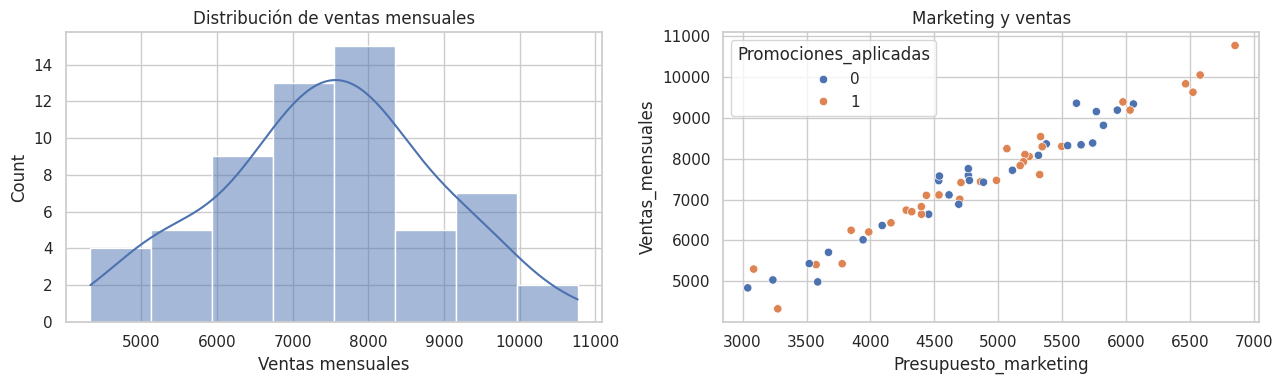

,Presupuesto_marketing,Ventas_mensuales,Nuevos_clientes,Promociones_aplicadas,Opinion_clientes
Presupuesto_marketing,1.000000,0.979829,-0.001209,0.066447,0.072673
Ventas_mensuales,0.979829,1.000000,-0.010144,0.053913,0.050662
Nuevos_clientes,-0.001209,-0.010144,1.000000,-0.091663,0.061015
Promociones_aplicadas,0.066447,0.053913,-0.091663,1.000000,0.216589
Opinion_clientes,0.072673,0.050662,0.061015,0.216589,1.000000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(datos["Ventas_mensuales"], kde=True, ax=axes[0])
axes[0].set_title("Distribución de ventas mensuales")
axes[0].set_xlabel("Ventas mensuales")

sns.scatterplot(data=datos, x="Presupuesto_marketing", y="Ventas_mensuales", hue="Promociones_aplicadas", ax=axes[1])
axes[1].set_title("Marketing y ventas")
plt.tight_layout()
plt.show()

display(datos[["Presupuesto_marketing", "Ventas_mensuales", "Nuevos_clientes",
               "Promociones_aplicadas", "Opinion_clientes"]].corr(numeric_only=True))

## 6. Modelo 1: regresión lineal para estimar las ventas

**Pregunta:** ¿cómo se relaciona el presupuesto de marketing con las ventas mensuales?

- Variable objetivo (`y`): `Ventas_mensuales`.
- Variable predictora (`X`): `Presupuesto_marketing`.
- Se reserva el 20 % de los registros para prueba.
- Métricas: MAE, RMSE y R².

El MAE y el RMSE se expresan en las unidades de ventas del archivo. R² mide qué proporción de la variabilidad de la variable objetivo explica el modelo en los datos evaluados; puede ser negativo si predice peor que una referencia basada en la media.

Intercepto: -96.935
Coeficiente de marketing: 1.559
MAE: 264.352
RMSE: 343.584
R²: 0.890


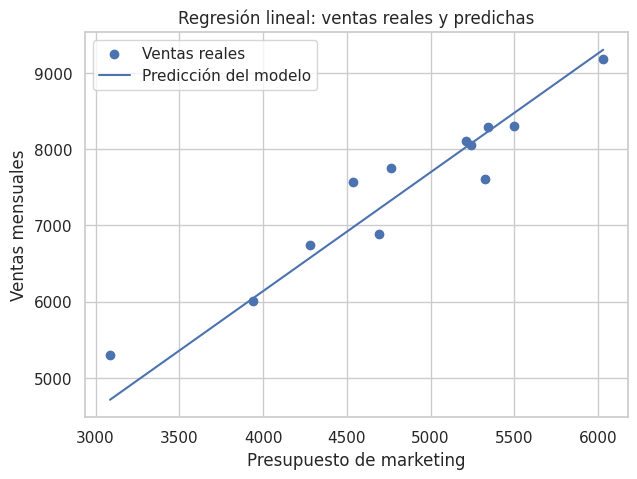

In [ ]:
X = datos[["Presupuesto_marketing"]]
y = datos["Ventas_mensuales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)
pred_lineal = modelo_lineal.predict(X_test)

mae = mean_absolute_error(y_test, pred_lineal)
rmse = np.sqrt(mean_squared_error(y_test, pred_lineal))
r2 = r2_score(y_test, pred_lineal)

print(f"Intercepto: {modelo_lineal.intercept_:.3f}")
print(f"Coeficiente de marketing: {modelo_lineal.coef_[0]:.3f}")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

plt.figure(figsize=(7, 5))
plt.scatter(X_test["Presupuesto_marketing"], y_test, label="Ventas reales")
orden = np.argsort(X_test["Presupuesto_marketing"].to_numpy())
plt.plot(
    X_test["Presupuesto_marketing"].to_numpy()[orden],
    pred_lineal[orden], label="Predicción del modelo"
)
plt.xlabel("Presupuesto de marketing")
plt.ylabel("Ventas mensuales")
plt.title("Regresión lineal: ventas reales y predichas")
plt.legend()
plt.show()

### Interpretación del modelo lineal
El coeficiente indica cuánto cambia la predicción de ventas, en promedio, cuando el presupuesto de marketing aumenta una unidad dentro de este modelo lineal. No debe interpretarse automáticamente como un efecto causal. Interpreta el coeficiente junto con MAE, RMSE y R², y considera que la muestra es pequeña.

## 7. Modelo 2: regresión logística para cumplimiento de la meta

**Pregunta:** ¿se cumple el objetivo de ventas?

El archivo no incluye una columna explícita con la meta comercial. Para hacer posible el ejercicio, se define una **meta operativa de referencia igual a la mediana de `Ventas_mensuales`** del conjunto. Esto divide los registros en ventas por debajo o por encima/igual a ese umbral; no equivale necesariamente a la meta real de la empresa.

- Objetivo binario: `1` si las ventas son iguales o superiores a la mediana, `0` en caso contrario.
- Predictores: presupuesto de marketing, nuevos clientes, promociones y opinión de clientes.
- Métricas: accuracy, matriz de confusión y AUC cuando ambas clases estén presentes en el conjunto de prueba.

Umbral de referencia (mediana de ventas): 7468.80


,count
Cumple_meta_referencia,
Igual o por encima,30
Por debajo del umbral,30


Accuracy: 1.000
Matriz de confusión:
[[6 0]
 [0 6]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12

AUC: 1.000


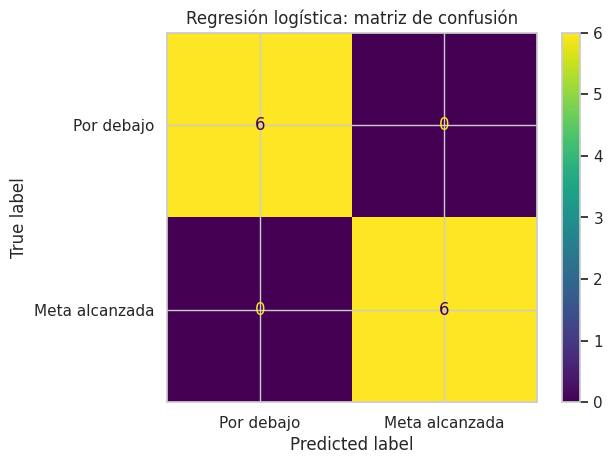

In [ ]:
umbral_ventas = datos["Ventas_mensuales"].median()
datos["Cumple_meta_referencia"] = (datos["Ventas_mensuales"] >= umbral_ventas).astype(int)

print(f"Umbral de referencia (mediana de ventas): {umbral_ventas:.2f}")
display(datos["Cumple_meta_referencia"].value_counts().rename(index={0:"Por debajo del umbral", 1:"Igual o por encima"}))

variables_log = [
    "Presupuesto_marketing", "Nuevos_clientes",
    "Promociones_aplicadas", "Opinion_clientes"
]
X = datos[variables_log]
y = datos["Cumple_meta_referencia"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

modelo_logistico = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=42))
])
modelo_logistico.fit(X_train, y_train)
pred_log = modelo_logistico.predict(X_test)
prob_log = modelo_logistico.predict_proba(X_test)[:, 1]

accuracy_log = accuracy_score(y_test, pred_log)
print(f"Accuracy: {accuracy_log:.3f}")
print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_log))
print("\nReporte de clasificación:")
print(classification_report(y_test, pred_log, zero_division=0))

if y_test.nunique() == 2:
    auc_log = roc_auc_score(y_test, prob_log)
    print(f"AUC: {auc_log:.3f}")
else:
    auc_log = np.nan
    print("AUC no calculable: el conjunto de prueba contiene una sola clase.")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_log, display_labels=["Por debajo", "Meta alcanzada"]
)
plt.title("Regresión logística: matriz de confusión")
plt.show()

### Interpretación de la regresión logística
La accuracy representa la proporción de clasificaciones correctas. La matriz de confusión permite distinguir aciertos y errores de cada clase. El AUC evalúa la capacidad de ordenar casos positivos por encima de negativos; 0.5 equivale aproximadamente al azar y 1 representa discriminación perfecta. Con solo 60 registros, estas métricas pueden variar mucho entre particiones.

## 8. Modelo 3: árbol de decisión para categorías de ventas

Se generan tres categorías —**bajas, medias y altas**— usando los terciles de ventas. Esta es una categorización relativa al conjunto, no una clasificación oficial de la empresa.

El árbol utiliza variables comerciales disponibles. Se excluyen `Ventas_mensuales` de los predictores porque es la variable con la que se construyen las categorías; incluirla causaría fuga de información.

Accuracy: 0.750

Reporte de clasificación:
              precision    recall  f1-score   support

       Altas       0.60      0.75      0.67         4
       Bajas       1.00      1.00      1.00         4
      Medias       0.67      0.50      0.57         4

    accuracy                           0.75        12
   macro avg       0.76      0.75      0.75        12
weighted avg       0.76      0.75      0.75        12



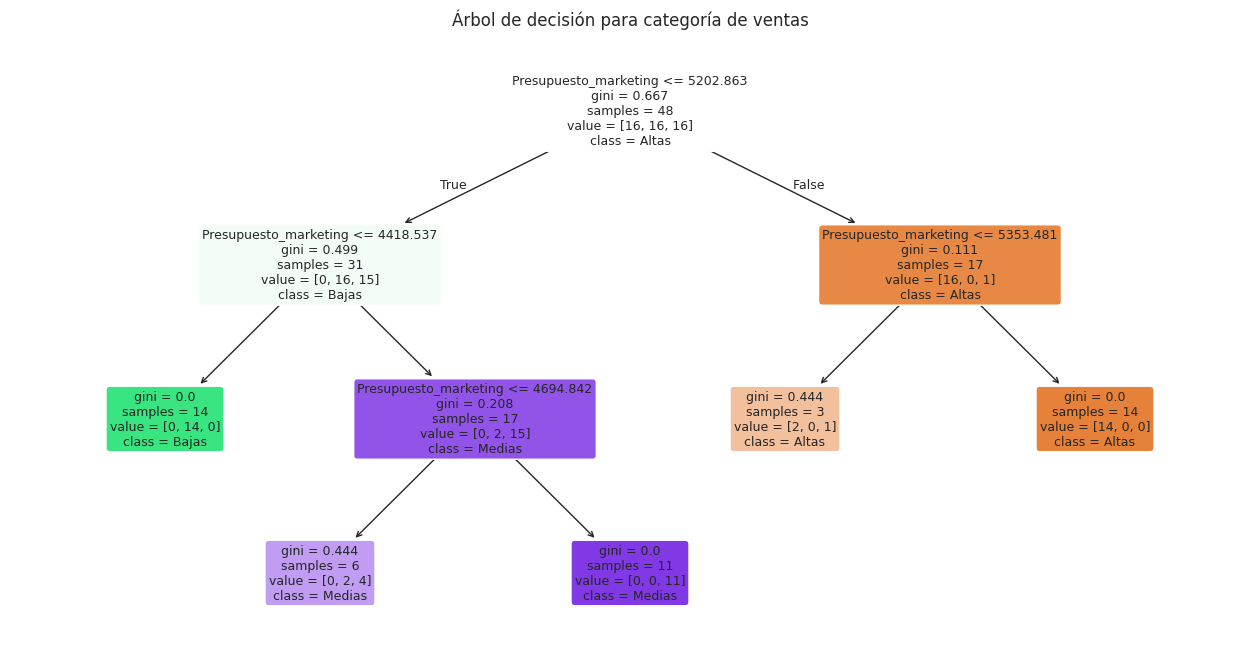

,Importancia
Presupuesto_marketing,1.0
Nuevos_clientes,0.0
Promociones_aplicadas,0.0
Opinion_clientes,0.0


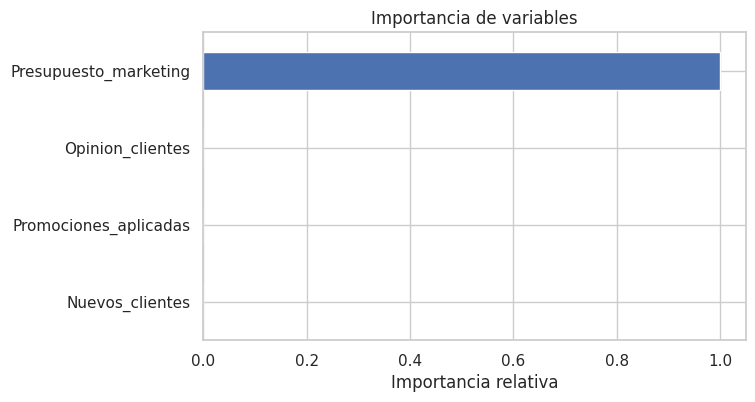

In [ ]:
datos["Categoria_ventas"] = pd.qcut(
    datos["Ventas_mensuales"],
    q=3,
    labels=["Bajas", "Medias", "Altas"],
    duplicates="drop"
)

variables_arbol = [
    "Presupuesto_marketing", "Nuevos_clientes",
    "Promociones_aplicadas", "Opinion_clientes"
]
X = datos[variables_arbol]
y = datos["Categoria_ventas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

modelo_arbol = DecisionTreeClassifier(
    max_depth=3, min_samples_leaf=3, random_state=42
)
modelo_arbol.fit(X_train, y_train)
pred_arbol = modelo_arbol.predict(X_test)

accuracy_arbol = accuracy_score(y_test, pred_arbol)
print(f"Accuracy: {accuracy_arbol:.3f}")
print("\nReporte de clasificación:")
print(classification_report(y_test, pred_arbol, zero_division=0))

plt.figure(figsize=(16, 8))
plot_tree(
    modelo_arbol,
    feature_names=variables_arbol,
    class_names=[str(c) for c in modelo_arbol.classes_],
    filled=True, rounded=True, fontsize=9
)
plt.title("Árbol de decisión para categoría de ventas")
plt.show()

importancias = pd.Series(
    modelo_arbol.feature_importances_, index=variables_arbol
).sort_values(ascending=False)
display(importancias.to_frame("Importancia"))
importancias.sort_values().plot(kind="barh", figsize=(7, 4), title="Importancia de variables")
plt.xlabel("Importancia relativa")
plt.show()

### Interpretación del árbol
Las reglas del árbol muestran combinaciones de variables asociadas con las categorías de ventas. La importancia de variables mide cuánto contribuyó cada variable a las divisiones del árbol entrenado; no demuestra causalidad y puede cambiar si se modifica la muestra o los parámetros.

## 9. Comparación de modelos

Las métricas de regresión y clasificación no son directamente intercambiables. La regresión lineal se evalúa con errores numéricos y R²; los modelos de clasificación con métricas como accuracy, precision, recall, matriz de confusión y, para el modelo logístico, AUC.

In [ ]:
comparacion = pd.DataFrame({
    "Modelo": ["Regresión lineal", "Regresión logística", "Árbol de decisión"],
    "Objetivo": [
        "Estimar ventas mensuales",
        "Clasificar cumplimiento de meta de referencia",
        "Clasificar ventas bajas, medias o altas"
    ],
    "Métricas": [
        f"MAE = {mae:.2f}; RMSE = {rmse:.2f}; R² = {r2:.3f}",
        f"Accuracy = {accuracy_log:.3f}; AUC = {auc_log:.3f}" if not np.isnan(auc_log) else f"Accuracy = {accuracy_log:.3f}; AUC no disponible",
        f"Accuracy = {accuracy_arbol:.3f}"
    ]
})
display(comparacion)
print("Nota: las métricas de regresión y clasificación no son directamente comparables.")


,Modelo,Objetivo,Métricas
0,Regresión lineal,Estimar ventas mensuales,MAE = 264.35; RMSE = 343.58; R² = 0.890
1,Regresión logística,Clasificar cumplimiento de meta de referencia,Accuracy = 1.000; AUC = 1.000
2,Árbol de decisión,"Clasificar ventas bajas, medias o altas",Accuracy = 0.750


Nota: las métricas de regresión y clasificación no son directamente comparables.


## 10. Predicción de ejemplo y toma de decisiones

La siguiente celda permite estimar ventas para un presupuesto de marketing que el usuario introduzca. Es una demostración del modelo, no una garantía de ventas. Evita extrapolar demasiado fuera del rango observado.

In [ ]:
presupuesto_ejemplo = float(input("Ingrese un presupuesto de marketing para estimar ventas: "))
rango_min = datos["Presupuesto_marketing"].min()
rango_max = datos["Presupuesto_marketing"].max()

prediccion_ejemplo = modelo_lineal.predict(pd.DataFrame({
    "Presupuesto_marketing": [presupuesto_ejemplo]
}))[0]

print(f"Rango de presupuestos observados: {rango_min:.2f} a {rango_max:.2f}")
print(f"Ventas estimadas por regresión lineal: {prediccion_ejemplo:.2f}")
if presupuesto_ejemplo < rango_min or presupuesto_ejemplo > rango_max:
    print("Advertencia: el presupuesto está fuera del rango observado; la estimación es una extrapolación.")

Ingrese un presupuesto de marketing para estimar ventas: 5496.714153
Rango de presupuestos observados: 3040.33 a 6852.28
Ventas estimadas por regresión lineal: 8471.51


## 11. Conclusiones

El desarrollo de esta práctica permitió comprender la importancia de la analítica de datos y las técnicas de Machine Learning como herramientas de apoyo para la toma de decisiones empresariales. A partir del conjunto de datos de ventas de zapatos, se estableció un proceso de análisis que incluyó la exploración de la información, la preparación y limpieza de los registros, la identificación de relaciones entre variables y la construcción de modelos predictivos orientados a mejorar la planificación comercial.

En primer lugar, el análisis exploratorio permitió examinar el comportamiento de las ventas mensuales y su posible relación con variables como el presupuesto de marketing, la cantidad de nuevos clientes, la aplicación de promociones y la opinión de los clientes. Las estadísticas descriptivas y las visualizaciones facilitaron la comprensión inicial de los datos y proporcionaron una base para la construcción de los modelos. Asimismo, la preparación de la información permitió establecer criterios de calidad, como la eliminación de registros duplicados y la exclusión de observaciones con valores faltantes en las variables requeridas.
En segundo lugar, el modelo de regresión lineal permitió abordar la estimación de las ventas mensuales a partir del presupuesto destinado al marketing. Esta técnica ofrece una aproximación cuantitativa que puede contribuir a la planificación de la inversión comercial. Sin embargo, su utilidad debe evaluarse mediante el error absoluto medio (MAE), la raíz del error cuadrático medio (RMSE) y el coeficiente de determinación (\(R^2\)), ya que estas métricas permiten determinar la magnitud de los errores de predicción y la capacidad explicativa del modelo. Por tanto, la conveniencia de utilizar sus estimaciones en decisiones reales dependerá de los resultados obtenidos en el conjunto de prueba.

En tercer lugar, la regresión logística permitió plantear un problema de clasificación relacionado con el cumplimiento de una meta de ventas de referencia. Debido a que el conjunto de datos no contiene una meta comercial explícita, se utilizó la mediana de las ventas como umbral para distinguir los registros por debajo de este valor de aquellos que lo igualan o superan. Este procedimiento hizo posible desarrollar el ejercicio de clasificación, aunque sus resultados no deben interpretarse como una medición definitiva del cumplimiento de los objetivos reales de la empresa. La exactitud, la matriz de confusión y el área bajo la curva ROC (AUC), cuando es calculable, permiten evaluar el desempeño del modelo y reconocer los errores que podrían afectar la toma de decisiones.



### Referencias
- Google Cloud. (s.f.). What is predictive analytics? https://cloud.google.com/learn/what-is-predictive-analytics?hl=es
- scikit-learn. Documentación de modelos y métricas: https://scikit-learn.org/stable/

